# 01 · Data loading and audit

**Dataset:** [`retkowski/ytseg`](https://huggingface.co/datasets/retkowski/ytseg), `text` configuration, pinned to revision
`4ee1c1fccc5a9e118ff0918f3df1e61aadca8970`. Each row is one YouTube video: its transcript as a list of sentences plus
the creator's chapters (start sentence and title).

This notebook covers:
1. Loading raw rows and converting them to the project's canonical record format.
2. Checking the label semantics.
3. Auditing the full splits, which found duplicate IDs and train/validation overlap.
4. Building the deduplicated variant used by every experiment.
5. Auditing the test split, done once and only after all configurations were frozen.
6. Corpus statistics, and the dev and pilot subsets used for LoRA training and model selection.

In [1]:
%matplotlib inline
import json, statistics
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
import pandas as pd
from nbcommon import *

pd.set_option("display.max_colwidth", 80)
RUN_GPU = False   # True only on the training/inference machine (needs the models and a GPU)
print("project:", ROOT.name, "| run outputs read from:", A.relative_to(ROOT))

project: FinalProject | run outputs read from: artifacts


## 1. Raw rows → canonical records

Raw rows carry the sentences (`text_ref`), a binary string marking the sentence that *starts* each internal chapter
(`target_binary_ref`), a marked copy of the transcript (`target_text_ref`) and the titles (`chapter_titles`).
`chaptering.data.canonicalize_row` converts a row into the canonical record. It also cross-checks the binary labels against
the `[CSTART]title[CEND]` markers and raises `DataValidationError` on any mismatch, so no label is ever guessed.

This cell streams a few training rows from the Hugging Face Hub, which needs internet. Offline, it falls back to the saved
canonical records.

In [2]:
from chaptering.data import DATASET, CONFIG, canonicalize_row, indexed_transcript, outline_target
REVISION = "4ee1c1fccc5a9e118ff0918f3df1e61aadca8970"
STREAM_FROM_HF = True

raw_rows = []
if STREAM_FROM_HF:
    try:
        from datasets import load_dataset
        stream = load_dataset(DATASET, CONFIG, revision=REVISION, split="train", streaming=True)
        for row in stream:
            raw_rows.append(row)
            if len(raw_rows) == 3:
                break
        print("raw fields:", sorted(raw_rows[0].keys()))
    except Exception as exc:  # offline or hub unavailable
        print("streaming unavailable, using saved canonical records:", type(exc).__name__)

if raw_rows:
    row = raw_rows[0]
    print("video:", row["video_id"], "| sentences:", len(row["text_ref"]), "| chapters:", len(row["chapter_titles"]))
    print("binary labels (first 60):", row["target_binary_ref"][:62])
    record = canonicalize_row(row, "train", REVISION)
else:
    record = load_jsonl(A / "data_audit/2026-11-16-resolved-v1/train.jsonl", limit=1)[0]
print(json.dumps({k: record[k] for k in ["schema_version", "video_id", "split", "reference", "provenance"]}, indent=1)[:1500])

Resolving data files:   0%|          | 0/125 [00:00<?, ?it/s]

raw fields: ['audio_path', 'channel_id', 'chapter_timestamps', 'chapter_titles', 'dominant_speaker_proportion', 'duration', 'num_speakers', 'raw_chapters', 'speaker_category', 'target_binary_ref', 'target_binary_wl', 'target_binary_wt', 'target_text_ref', 'target_text_ts_ref', 'target_ts', 'text_ref', 'text_wl', 'text_wt', 'video_id']
video: q5D55G7Ejs8 | sentences: 946 | chapters: 9
binary labels (first 60): |=000000000000000010000000000000000000000000000000000000000000
{
 "schema_version": 1,
 "video_id": "q5D55G7Ejs8",
 "split": "train",
 "reference": {
  "chapter_starts": [
   0,
   16,
   301,
   373,
   429,
   477,
   601,
   790,
   926
  ],
  "chapter_titles": [
   "Introduction",
   "iOS",
   "Ecosystem",
   "watchOS",
   "Health",
   "Mac",
   "macOS",
   "iPadOS",
   "Outro"
  ]
 },
 "provenance": {
  "dataset": "retkowski/ytseg",
  "config": "text",
  "revision": "4ee1c1fccc5a9e118ff0918f3df1e61aadca8970",
  "label_semantics": "internal_chapter_start_sentence_index",
  "al

In [3]:
# The model only ever sees the numbered sentences; the reference stays outside every generation payload.
print(indexed_transcript(record)[:800], "...")
print()
print("training target:", json.dumps(outline_target(record))[:400])

[0] ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ Tim Cook: Good morning, and welcome to WWDC.
[1] We have a big day of announcements about our latest technologies and platforms.
[2] These platforms, and the products they drive, deliver amazing experiences for our users and provide developers with incredible opportunities so they can use their superpowers to innovate, create, and collaborate, making apps that continue to change the world.
[3] And WWDC is designed to give this community what they need to do their very best work.
[4] We love to support our developers beyond WWDC with comprehensive world-class support and other important initiatives.
[5] We just opened our brand-new Developers Center across from Apple Park where developers can engage with our engineers.
[6] And to reach our global community, this past fal ...

training target: {"chapters": [{"start": 0, "title": "Introduction"}, {"start": 16, "title": "iOS"}, {"start": 301, "title": "Ecosystem"}, {"start": 373, "title": "watchOS"}, {"start": 429, "tit

## 2. Full-split audit (`scripts/audit_data.py`)

This is a CPU-only pass over every train and validation row at the pinned revision. Test rows were only counted by ID; their content was not read. The audit found:
* **Duplicate video IDs**: 17 in train, 1 in validation. Most are exact copies; a few have *conflicting* content.
* **Train/validation overlap**: some validation videos also appear in train.

In [4]:
run(["python", "scripts/audit_data.py", "--output", "artifacts/data_audit/source-audit", "--revision", REVISION], RUN_GPU)
audit = load_json(A / "data_audit/source-audit/audit.json")
rows = []
for split in ["train", "validation"]:
    s = audit["splits"][split]
    rows.append({"split": split, "rows": s["rows_seen"], "valid rows": s["valid_rows"], "unique ids": s["unique_ids"],
                 "duplicate ids": len(s["duplicate_ids"]),
                 "median sentences": s["sentence_counts"]["quantiles"]["0.5"],
                 "max sentences": s["sentence_counts"]["quantiles"]["1"],
                 "mean chapters": round(s["chapter_counts"]["mean"], 2)})
display(pd.DataFrame(rows).set_index("split"))
print("split overlaps:", json.dumps(audit["split_overlaps"], indent=1)[:600])
print("integrity gate passed:", audit["full_integrity_gate_passed"])

[not run here; RUN_GPU=False]  $ python scripts/audit_data.py --output artifacts/data_audit/source-audit --revision 4ee1c1fccc5a9e118ff0918f3df1e61aadca8970


,rows,valid rows,unique ids,duplicate ids,median sentences,max sentences,mean chapters
split,,,,,,,
train,16404,16404,16387,17,113,6498,9.11
validation,1447,1447,1446,1,115,1895,9.24


split overlaps: {
 "train__validation": {
  "count": 4,
  "video_ids": [
   "VKmOXCEq-6A",
   "nP-nMZpLM1A",
   "xZ3k7Fd6_eU",
   "z6qATR0VLnk"
  ]
 },
 "train__test": {
  "count": 0,
  "video_ids": []
 },
 "validation__test": {
  "count": 0,
  "video_ids": []
 }
}
integrity gate passed: False


## 3. Deduplicated / quarantined variant (`scripts/resolve_duplicates.py`)

The original files are kept untouched. A declared variant is derived from them:
* Every training row whose ID also appears in validation is removed.
* For exact duplicates, the first copy is kept.
* IDs with conflicting copies are quarantined, never resolved by picking one.

In [5]:
run(["python", "scripts/resolve_duplicates.py", "--source", "artifacts/data_audit/source-audit",
     "--output", "artifacts/data_audit/2026-11-16-resolved-v1"], RUN_GPU)
res = load_json(A / "data_audit/2026-11-16-resolved-v1/resolution.json")
for key, text in res["policy"].items():
    print(f"- {key}: {text}")
counts = res["original_and_resolved_counts"]
display(pd.DataFrame({split: {k: v for k, v in c.items() if isinstance(v, int)} for split, c in counts.items()}))
print("resolved gate passed:", res["resolved_integrity_gate_passed"])

[not run here; RUN_GPU=False]  $ python scripts/resolve_duplicates.py --source artifacts/data_audit/source-audit --output artifacts/data_audit/2026-11-16-resolved-v1
- training_exclusion: Remove every training row whose video_id occurs in the ORIGINAL validation file, even if that validation ID is quarantined.
- identical_duplicates: Keep first source occurrence within each split; identity is exact sentences+reference, excluding provenance.
- conflicts: Quarantine all occurrences of any within-split ID with multiple content fingerprints; never choose one variant.
- overlapping_removal_reasons: Conflict quarantine includes cross-split-excluded rows; exclusive_removed_counts avoids double counting.
- partitions: No record changes partition; output files are unmodified source-record subsets.
- smoke: Regenerated at sentence-count quantiles .1/.5/.9, ties by video_id, before model results.
- test: No test content read. Inherit zero overlap only from hash-verified full source audit and subs

,train,validation
original_rows,16404,1447
original_unique_ids,16387,1446
resolved_rows,16377,1446
resolved_unique_ids,16377,1446
original_duplicate_id_occurrences,17,1
identical_duplicate_rows_removed_after_exclusions,11,1
quarantined_conflict_rows,12,0
validation_priority_excluded_rows,4,0
conflict_rows_also_excluded_by_validation_priority,0,0


resolved gate passed: True


## 4. Test split (read once, after the freeze)

`scripts/prepare_test.py` canonicalizes the test split only after `configs/frozen_test.json` was written. It confirms that every row is valid and unique and that none overlaps the resolved train/validation sets.

In [6]:
test_audit = load_json(A / "data_audit/2026-11-17-test-v1/test_audit.json")
print({k: test_audit[k] for k in ["rows_seen", "valid_rows", "invalid_rows", "unique_ids", "duplicate_ids",
                                   "overlap_with_resolved_train_validation", "passed"]})

{'rows_seen': 1448, 'valid_rows': 1448, 'invalid_rows': [], 'unique_ids': 1448, 'duplicate_ids': [], 'overlap_with_resolved_train_validation': [], 'passed': True}


## 5. Corpus statistics (canonical records)

In [7]:
validation = load_jsonl(A / "data_audit/2026-11-16-resolved-v1/validation.jsonl")
test = load_jsonl(TEST_RECORDS)
train = load_jsonl(A / "data_audit/2026-11-16-resolved-v1/train.jsonl")

def stats(records):
    sentences = [len(r["sentences"]) for r in records]
    chapters = [len(r["reference"]["chapter_starts"]) for r in records]
    lengths = [n / c for n, c in zip(sentences, chapters)]
    return {"videos": len(records), "median sentences": statistics.median(sentences), "max sentences": max(sentences),
            "median chapters": statistics.median(chapters), "mean chapters": round(statistics.mean(chapters), 2),
            "median sentences / chapter": round(statistics.median(lengths), 1)}

display(pd.DataFrame({"train (resolved)": stats(train), "validation (resolved)": stats(validation), "test": stats(test)}).T)

,videos,median sentences,max sentences,median chapters,mean chapters,median sentences / chapter
train (resolved),16377.0,113.0,6498.0,8.0,9.09,13.2
validation (resolved),1446.0,115.0,1895.0,8.0,9.23,13.5
test,1448.0,113.0,2772.0,8.0,9.18,12.9


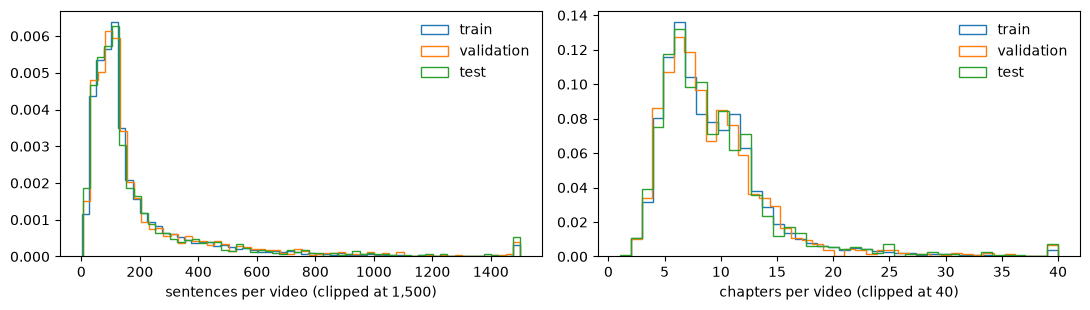

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for name, records in [("train", train), ("validation", validation), ("test", test)]:
    axes[0].hist([min(len(r["sentences"]), 1500) for r in records], bins=60, histtype="step", density=True, label=name)
    axes[1].hist([min(len(r["reference"]["chapter_starts"]), 40) for r in records], bins=40, histtype="step", density=True, label=name)
axes[0].set_xlabel("sentences per video (clipped at 1,500)"); axes[1].set_xlabel("chapters per video (clipped at 40)")
for ax in axes: ax.legend(frameon=False)
plt.tight_layout()

## 6. Dev and pilot subsets (`scripts/prepare_windows.py`)

* **LoRA training set:** 1,000 videos drawn from the resolved training split. These are the *pilot-scale* adapters.
* **Dev set:** 200 validation videos, used for model selection.

Selection is gold-free: videos are binned by length and then drawn with a seeded hash. The full validation set (1,446 videos) is windowed separately for the long-transcript analysis.

In [9]:
manifest = load_json(DEV_PACK / "manifest.json")
print(manifest["selection_policy"])
print(json.dumps(manifest["settings"], indent=1))
for split in ["train", "validation"]:
    p = manifest["statistics"][split]["processed"]
    print(split, {k: p[k] for k in ["attempted_videos", "successful_videos", "windows", "owned_sentences"]})

four contiguous bins sorted(sentence_count,video_id); round-robin quotas; seeded SHA256 video-ID rank within each bin; no gold used
{
 "train_videos": 1000,
 "validation_videos": 200,
 "input_tokens": 8192,
 "core_sentences": 100000,
 "context_sentences": 16,
 "seed": 393,
 "census_all": false,
 "core_search": "bisect"
}
train {'attempted_videos': 1000, 'successful_videos': 1000, 'windows': 1306, 'owned_sentences': 199943}
validation {'attempted_videos': 200, 'successful_videos': 200, 'windows': 270, 'owned_sentences': 41494}
